In [1]:
import bbknn
import scanpy as sc
import bin2cell as b2c
import anndata

In [2]:
adata1 = sc.read_h5ad("/Users/mayathompson/research/MIA1/MIA1_adata_gex.h5ad")
adata2 = sc.read_h5ad("adata_pca_expanded_with_gex.h5ad")
adata3 = sc.read_h5ad("/Users/mayathompson/research/MIA3/MIA3_adata_gex.h5ad")

In [3]:
cdata1 = b2c.bin_to_cell(
    adata1,
    labels_key="labels_joint",
    spatial_keys=["spatial", "spatial_cropped_150_buffer"]
)

cdata2 = b2c.bin_to_cell(
    adata2,
    labels_key="labels_joint",
    spatial_keys=["spatial", "spatial_cropped_150_buffer"]
)

cdata3 = b2c.bin_to_cell(
    adata3,
    labels_key="labels_joint",
    spatial_keys=["spatial", "spatial_cropped_150_buffer"]
)

In [4]:
processed = []
for cdata in [cdata1, cdata2, cdata3]:
    genes_to_keep = [g for g in cdata.var_names if not g.startswith('MT') and g not in ['TMSB4X', 'IGKC']]
    cdata = cdata[:, genes_to_keep].copy()
    sc.pp.filter_cells(cdata, min_genes=100)
    sc.pp.filter_genes(cdata, min_cells=3)
    sc.pp.normalize_total(cdata)
    sc.pp.log1p(cdata)
    cdata.raw = cdata   
    processed.append(cdata)

cdata_combined = anndata.concat(
    processed,
    label="batch",
    keys=["MIA1", "MIA2", "MIA3"],
    index_unique="-"
) # check unique obs

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [5]:
#print(cdata1.X)
print(cdata_combined.raw)
print(cdata_combined.raw.X[:5,:5].toarray() if hasattr(cdata_combined.raw.X, 'toarray') else cdata_combined.raw.X[:5,:5])

Raw AnnData with n_obs × n_vars = 133377 × 13814
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


In [6]:
import numpy as np

X = cdata_combined.raw.X
X = X.toarray() if hasattr(X, 'toarray') else X

print("min:", X.min())
print("max:", X.max())
print("any negative values?", (X < 0).any())

# look at a row that actually has expression
nonzero_row = np.where(X.sum(axis=1) > 0)[0][0]
print(X[nonzero_row, :20])

min: 0.0
max: 5.5667029754556445
any negative values? False
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [7]:
# select highly variable genes
sc.pp.highly_variable_genes(cdata_combined, n_top_genes=2000, batch_key = "batch") #find hvg within each batch
#cdata_combined = cdata_combined[:, cdata_combined.var.highly_variable].copy() (should this stay commented out)
#cdata_combined.raw = cdata_combined

In [8]:
# scaling and pca
sc.pp.scale(cdata_combined)
sc.pp.pca(cdata_combined, n_comps = 30)
#sc.tl.pca(cdata_combined, n_comps=30) # learns sructure, not just preprocessing

functools.py (889): zero-centering a sparse array/matrix densifies it.


In [9]:
# bbknn
sc.external.pp.bbknn(cdata_combined, batch_key="batch", n_pcs=30)

In [10]:
cdata_combined.write_h5ad("cdata_combined_integrated.h5ad", compression="gzip") #save h5ad file

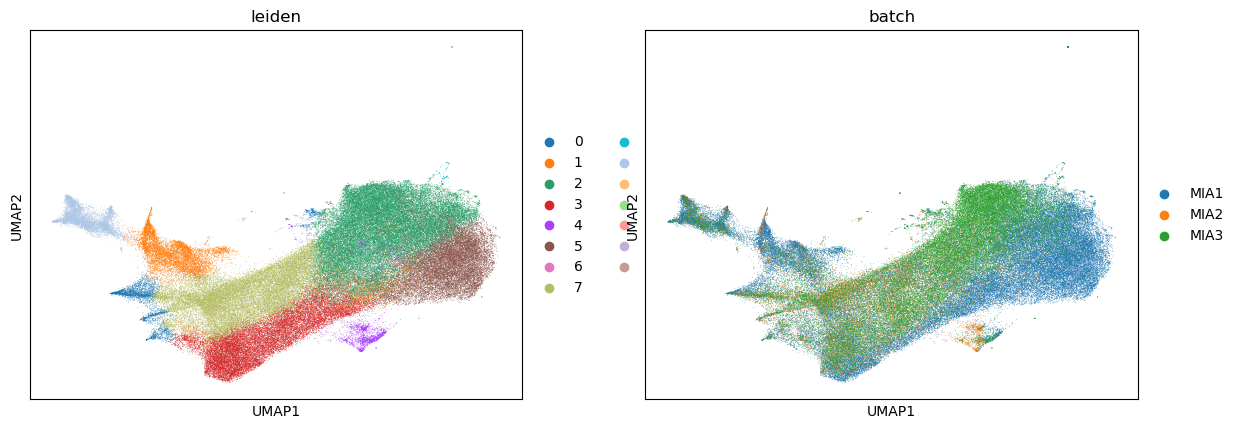

In [11]:
sc.tl.umap(cdata_combined, min_dist=0.1, spread=1.0)
sc.tl.leiden(cdata_combined, flavor="igraph", n_iterations=2, resolution=0.5)
sc.pl.umap(cdata_combined, color=["leiden", "batch"])

In [ ]:
# Manual Cell Type Annotation
for res in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    sc.tl.leiden(cdata_combined, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph")

sc.pl.umap(
    cdata_combined,
    color=["leiden_res_0.20", "leiden_res_0.30", "leiden_res_0.40", "leiden_res_0.50", "leiden_res_0.60", "leiden_res_0.70"],
    legend_loc="on data",
)

Exception ignored in: <class 'SystemError'>
Traceback (most recent call last):
  File "/opt/anaconda3/envs/stardist-env/lib/python3.10/site-packages/scanpy/_utils/random.py", line 50, in getrandbits
    return self._rng.tomaxint() & ((1 << k) - 1)
  File "numpy/random/mtrand.pyx", line 667, in numpy.random.mtrand.RandomState.tomaxint
SystemError: <built-in method __enter__ of _thread.lock object at 0x375453400> returned a result with an exception set


In [ ]:
import scanpy as sc

# Set the output directory (scanpy will create it if it doesn't exist)
sc.settings.figdir = "figures"

for res in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    sc.pl.umap(
        cdata_combined,
        color=f"leiden_res_{res:4.2f}",
        legend_loc="on data",
        title=f"Leiden Clustering (Resolution {res:.2f})",
        save=f"_leiden_res_{res:.2f}.png",  # gets prefixed with "umap"
        show=False
    )

In [ ]:
resolutions = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

for res in resolutions:
    res_key = f"leiden_res_{res:.2f}"
    
    sc.tl.rank_genes_groups(
        cdata_combined,
        groupby=res_key,
        method="wilcoxon",
        use_raw=True
    )
    
    sc.pl.rank_genes_groups_dotplot(
        cdata_combined,
        groupby=res_key,
        standard_scale="var",
        n_genes=5,
        use_raw=True
    )
    
    df = sc.get.rank_genes_groups_df(cdata_combined, None)
    significant_genes = df[df["pvals_adj"] < 0.05]
    significant_genes.to_csv(f"{res:.1f}_leiden_integration.csv", index=False)
    
    print(f"Saved resolution {res} — {len(significant_genes)} significant genes")